# Customer Feedback Intelligence

## Goal
Build and evaluate a classifier for positive and negative customer
review sentences, then present the results in a business dashboard.

## Dataset
Amazon subset of UCI Sentiment Labelled Sentences.

- Labels: 0 = negative, 1 = positive
- Unit of analysis: a review sentence, not necessarily a complete review
- No neutral class
- This curated sample does not represent overall customer satisfaction.

Source: https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences

In [1]:
from pathlib import Path
import csv

import pandas as pd
from IPython.display import display

# Works when the notebook runs from the project root or notebooks folder.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "sentiment labelled sentences"
    / "amazon_cells_labelled.txt"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df_raw = pd.read_csv(
    DATA_PATH,
    sep="\t",
    header=None,
    names=["text", "label"],
    quoting=csv.QUOTE_NONE,
    encoding="utf-8",
)

print(f"Rows: {len(df_raw):,}")
display(df_raw.head())

Rows: 1,000


,text,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [2]:
# Keep the raw data unchanged.
df = df_raw.copy()

# Normalize whitespace only for duplicate detection.
normalized_text = (
    df["text"]
    .fillna("")
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

duplicate_check = pd.DataFrame({
    "normalized_text": normalized_text,
    "label": df["label"],
})

conflicting_texts = (
    duplicate_check.groupby("normalized_text")["label"]
    .nunique()
    .gt(1)
    .sum()
)

quality = pd.Series({
    "rows": len(df),
    "missing_text": int(df["text"].isna().sum()),
    "blank_text": int(normalized_text.eq("").sum()),
    "missing_labels": int(df["label"].isna().sum()),
    "unexpected_labels": int(
        (~df["label"].isin([0, 1]) & df["label"].notna()).sum()
    ),
    "exact_duplicate_rows": int(df.duplicated().sum()),
    "repeated_normalized_texts": int(normalized_text.duplicated().sum()),
    "texts_with_conflicting_labels": int(conflicting_texts),
}, name="count")

display(quality.to_frame())

label_counts = (
    df["label"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Negative", 1: "Positive"})
)

display(label_counts.rename("records").to_frame())

,count
rows,1000
missing_text,0
blank_text,0
missing_labels,0
unexpected_labels,0
exact_duplicate_rows,10
repeated_normalized_texts,13
texts_with_conflicting_labels,0


,records
label,
Negative,500
Positive,500


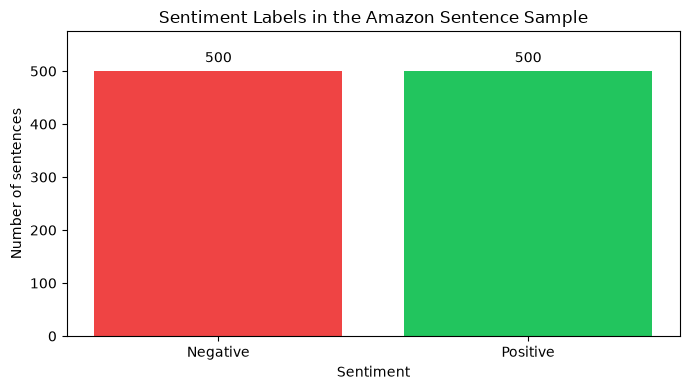

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    label_counts.index.to_list(),
    label_counts.to_numpy(dtype=int),
    color=["#ef4444", "#22c55e"],
)

ax.bar_label(bars, padding=4)
ax.set_title("Sentiment Labels in the Amazon Sentence Sample")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of sentences")
ax.set_ylim(0, max(label_counts.max() * 1.15, 1))

fig.tight_layout()

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "sentiment_distribution.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()

In [4]:
df["word_count"] = (
    df["text"]
    .fillna("")
    .str.split()
    .str.len()
)

display(
    df.groupby("label")["word_count"]
    .describe()
    .rename(index={0: "Negative", 1: "Positive"})
    .round(2)
)

repeated_mask = normalized_text.duplicated(keep=False)

print(
    "Rows belonging to repeated normalized texts:",
    int(repeated_mask.sum()),
)

display(
    df.loc[repeated_mask, ["text", "label"]]
    .assign(normalized_text=normalized_text.loc[repeated_mask])
    .sort_values("normalized_text")
)

print("\nData-quality summary:")
display(quality.to_frame())

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Negative,500.0,10.58,6.58,1.0,5.0,10.0,15.0,30.0
Positive,500.0,9.91,6.79,1.0,4.0,8.0,14.0,30.0


Rows belonging to repeated normalized texts: 24


,text,label,normalized_text
748,Does not fit.,0,does not fit.
446,Does not fit.,0,does not fit.
543,Don't buy this product.,0,don't buy this product.
180,Don't buy this product.,0,don't buy this product.
402,Excellent product for the price.,1,excellent product for the price.
892,Excellent product for the price.,1,excellent product for the price.
187,Great phone!.,1,great phone!.
285,Great phone!.,1,great phone!.
896,Great phone.,1,great phone.
647,Great phone.,1,great phone.



Data-quality summary:


,count
rows,1000
missing_text,0
blank_text,0
missing_labels,0
unexpected_labels,0
exact_duplicate_rows,10
repeated_normalized_texts,13
texts_with_conflicting_labels,0


In [2]:
from pathlib import Path
import csv

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "sentiment labelled sentences"
    / "amazon_cells_labelled.txt"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df_raw = pd.read_csv(
    DATA_PATH,
    sep="\t",
    header=None,
    names=["text", "label"],
    quoting=csv.QUOTE_NONE,
    encoding="utf-8",
)

print(f"Loaded {len(df_raw):,} sentences.")
display(df_raw.head())

Loaded 1,000 sentences.


,text,label
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


In [4]:
from pathlib import Path
import csv

import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split


# --------------------------------------------------
# 1. Locate and load the original dataset
# --------------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "sentiment labelled sentences"
    / "amazon_cells_labelled.txt"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(
    DATA_PATH,
    sep="\t",
    header=None,
    names=["text", "label"],
    quoting=csv.QUOTE_NONE,
    encoding="utf-8",
)


# --------------------------------------------------
# 2. Check and clean the data
# --------------------------------------------------

prepared = df_raw.copy()

# Normalize only for duplicate detection.
# Original wording is preserved in the text column.
prepared["normalized_text"] = (
    prepared["text"]
    .fillna("")
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

invalid_mask = (
    prepared["normalized_text"].eq("")
    | ~prepared["label"].isin([0, 1])
)

invalid_rows = prepared.loc[invalid_mask].copy()
prepared = prepared.loc[~invalid_mask].copy()

# Find sentences that have conflicting labels.
labels_per_text = (
    prepared.groupby("normalized_text")["label"].nunique()
)

conflicting_texts = labels_per_text[
    labels_per_text > 1
].index

conflict_mask = prepared["normalized_text"].isin(conflicting_texts)

conflict_rows = prepared.loc[conflict_mask].copy()
prepared = prepared.loc[~conflict_mask].copy()

duplicate_rows_removed = int(
    prepared.duplicated(subset="normalized_text").sum()
)

clean_df = (
    prepared
    .drop_duplicates(subset="normalized_text")
    .reset_index(drop=True)
)

clean_df["label"] = clean_df["label"].astype(int)

assert clean_df["normalized_text"].is_unique
assert clean_df["normalized_text"].ne("").all()
assert clean_df["label"].isin([0, 1]).all()

cleaning_summary = pd.Series(
    {
        "original_rows": len(df_raw),
        "invalid_rows_removed": len(invalid_rows),
        "conflicting_label_rows_excluded": len(conflict_rows),
        "duplicate_rows_removed": duplicate_rows_removed,
        "clean_rows_remaining": len(clean_df),
    },
    name="count",
)

print("CLEANING SUMMARY")
display(cleaning_summary.to_frame())


# --------------------------------------------------
# 3. Create training, validation, and test sets
# --------------------------------------------------

development_df, test_df = train_test_split(
    clean_df,
    test_size=0.20,
    stratify=clean_df["label"],
    random_state=42,
)

train_df, validation_df = train_test_split(
    development_df,
    test_size=0.25,
    stratify=development_df["label"],
    random_state=42,
)

train_texts = set(train_df["normalized_text"])
validation_texts = set(validation_df["normalized_text"])
test_texts = set(test_df["normalized_text"])

assert train_texts.isdisjoint(validation_texts)
assert train_texts.isdisjoint(test_texts)
assert validation_texts.isdisjoint(test_texts)

assert (
    len(train_df) + len(validation_df) + len(test_df)
    == len(clean_df)
)

split_summary = pd.DataFrame(
    [
        {
            "split": name,
            "sentences": len(frame),
            "negative": int(frame["label"].eq(0).sum()),
            "positive": int(frame["label"].eq(1).sum()),
        }
        for name, frame in [
            ("Training", train_df),
            ("Validation", validation_df),
            ("Test", test_df),
        ]
    ]
)

print("SPLIT SUMMARY")
display(split_summary)


# --------------------------------------------------
# 4. Save the outputs
# --------------------------------------------------

clean_df.to_csv(
    PROCESSED_DIR / "amazon_sentences_clean.csv",
    index=False,
)

invalid_rows.to_csv(
    PROCESSED_DIR / "invalid_rows_review.csv",
    index=False,
)

conflict_rows.to_csv(
    PROCESSED_DIR / "conflicting_labels_review.csv",
    index=False,
)

for name, frame in [
    ("train", train_df),
    ("validation", validation_df),
    ("test", test_df),
]:
    frame.to_csv(
        PROCESSED_DIR / f"{name}.csv",
        index=False,
    )

cleaning_summary.to_csv(
    PROCESSED_DIR / "cleaning_summary.csv",
)

split_summary.to_csv(
    PROCESSED_DIR / "split_summary.csv",
    index=False,
)

print("All outputs saved.")
print("Verified: no normalized sentence crosses dataset splits.")
print("Keep the test set aside until final evaluation.")

CLEANING SUMMARY


,count
original_rows,1000
invalid_rows_removed,0
conflicting_label_rows_excluded,0
duplicate_rows_removed,13
clean_rows_remaining,987


SPLIT SUMMARY


,split,sentences,negative,positive
0,Training,591,297,294
1,Validation,198,99,99
2,Test,198,100,98


All outputs saved.
Verified: no normalized sentence crosses dataset splits.
Keep the test set aside until final evaluation.


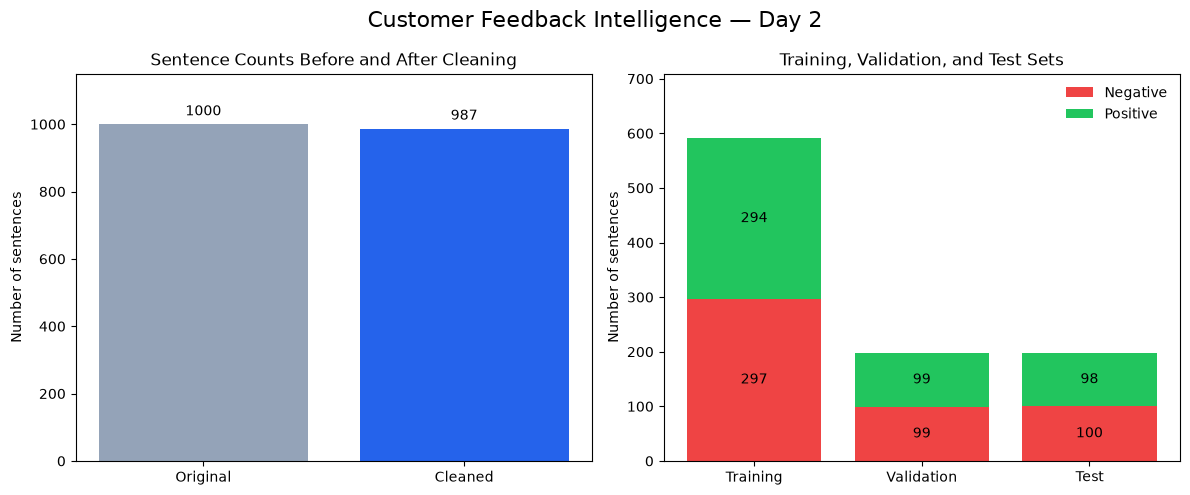

Cleaning results:


,count
original_rows,1000
invalid_rows_removed,0
conflicting_label_rows_excluded,0
duplicate_rows_removed,13
clean_rows_remaining,987


Dataset splits:


,split,sentences,negative,positive
0,Training,591,297,294
1,Validation,198,99,99
2,Test,198,100,98


In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: original versus cleaned dataset.
dataset_counts = [len(df_raw), len(clean_df)]

bars = axes[0].bar(
    ["Original", "Cleaned"],
    dataset_counts,
    color=["#94a3b8", "#2563eb"],
)

axes[0].bar_label(bars, padding=4)
axes[0].set_title("Sentence Counts Before and After Cleaning")
axes[0].set_ylabel("Number of sentences")
axes[0].set_ylim(0, max(dataset_counts) * 1.15)

# Chart 2: sentiment counts within each dataset split.
positions = list(range(len(split_summary)))
negative_counts = split_summary["negative"].to_numpy(dtype=int)
positive_counts = split_summary["positive"].to_numpy(dtype=int)

negative_bars = axes[1].bar(
    positions,
    negative_counts,
    color="#ef4444",
    label="Negative",
)

positive_bars = axes[1].bar(
    positions,
    positive_counts,
    bottom=negative_counts,
    color="#22c55e",
    label="Positive",
)

axes[1].bar_label(negative_bars, label_type="center")
axes[1].bar_label(positive_bars, label_type="center")

axes[1].set_xticks(
    positions,
    split_summary["split"].to_list(),
)

axes[1].set_title("Training, Validation, and Test Sets")
axes[1].set_ylabel("Number of sentences")
axes[1].set_ylim(
    0,
    max(split_summary["sentences"]) * 1.2,
)

axes[1].legend(
    loc="upper right",
    frameon=False,
)

fig.suptitle(
    "Customer Feedback Intelligence — Day 2",
    fontsize=16,
)

fig.tight_layout()

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

fig.savefig(
    FIGURES_DIR / "day2_data_preparation.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print("Cleaning results:")
display(cleaning_summary.to_frame())

print("Dataset splits:")
display(split_summary)

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
validation_df = pd.read_csv(PROCESSED_DIR / "validation.csv")

assert train_df["text"].notna().all()
assert validation_df["text"].notna().all()

assert set(train_df["normalized_text"]).isdisjoint(
    set(validation_df["normalized_text"])
)

X_train = train_df["text"].to_list()
y_train = train_df["label"].to_numpy(dtype=int)

X_validation = validation_df["text"].to_list()
y_validation = validation_df["label"].to_numpy(dtype=int)

print(f"Training sentences: {len(train_df)}")
print(f"Validation sentences: {len(validation_df)}")
print("The test set has not been loaded.")

Training sentences: 591
Validation sentences: 198
The test set has not been loaded.


In [3]:
import numpy as np

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.pipeline import Pipeline


# --------------------------------------------------
# 1. Train the dummy baseline
# --------------------------------------------------

# DummyClassifier ignores these feature values.
# NumPy arrays satisfy the expected matrix type.
dummy_train = np.zeros((len(y_train), 1))
dummy_validation = np.zeros((len(y_validation), 1))

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(dummy_train, y_train)

baseline_predictions = baseline.predict(dummy_validation)


# --------------------------------------------------
# 2. Train TF-IDF + logistic regression
# --------------------------------------------------

sentiment_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True,
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42,
        ),
    ),
])

# Fit the vocabulary and classifier on training data only.
sentiment_model.fit(X_train, y_train)

model_predictions = sentiment_model.predict(X_validation)


# --------------------------------------------------
# 3. Compare validation results
# --------------------------------------------------

results = []

for name, predictions in [
    ("Dummy baseline", baseline_predictions),
    ("TF-IDF + logistic regression", model_predictions),
]:
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_validation, predictions),
        "macro_precision": precision_score(
            y_validation,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "macro_recall": recall_score(
            y_validation,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro",
            zero_division=0,
        ),
    })

validation_results = pd.DataFrame(results)

display(validation_results.round(3))

validation_results.to_csv(
    REPORTS_DIR / "validation_model_comparison.csv",
    index=False,
)

print("Validation results saved. The test set remains untouched.")

,model,accuracy,macro_precision,macro_recall,macro_f1
0,Dummy baseline,0.500,0.250,0.500,0.333
1,TF-IDF + logistic regression,0.793,0.794,0.793,0.793


Validation results saved. The test set remains untouched.


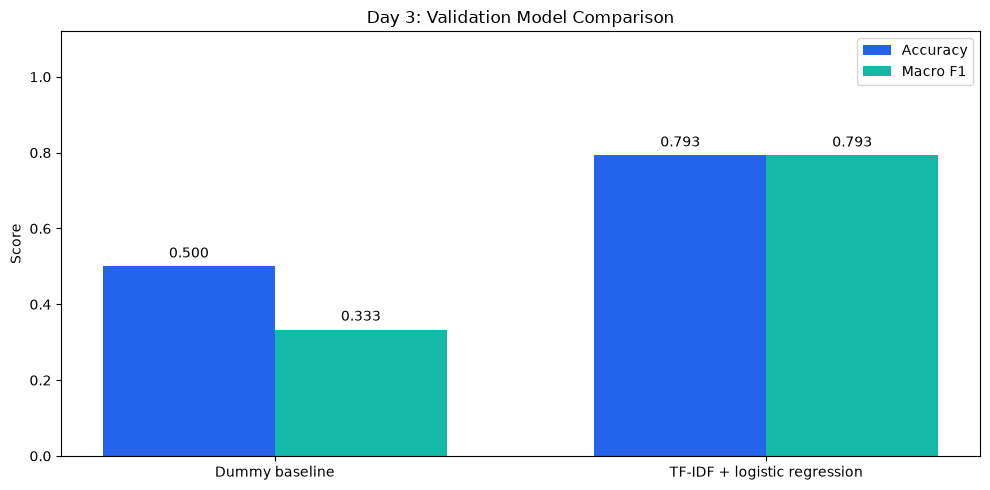

,model,accuracy,macro_precision,macro_recall,macro_f1
0,Dummy baseline,0.500,0.250,0.500,0.333
1,TF-IDF + logistic regression,0.793,0.794,0.793,0.793


In [4]:
import matplotlib.pyplot as plt

FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

positions = np.arange(len(validation_results))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

accuracy_bars = ax.bar(
    positions - width / 2,
    validation_results["accuracy"].to_numpy(dtype=float),
    width,
    label="Accuracy",
    color="#2563eb",
)

f1_bars = ax.bar(
    positions + width / 2,
    validation_results["macro_f1"].to_numpy(dtype=float),
    width,
    label="Macro F1",
    color="#14b8a6",
)

ax.bar_label(accuracy_bars, fmt="%.3f", padding=4)
ax.bar_label(f1_bars, fmt="%.3f", padding=4)

ax.set_xticks(
    positions,
    ["Dummy baseline", "TF-IDF + logistic regression"],
)

ax.set_ylim(0, 1.12)
ax.set_ylabel("Score")
ax.set_title("Day 3: Validation Model Comparison")
ax.legend()

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "day3_validation_comparison.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

display(validation_results.round(3))

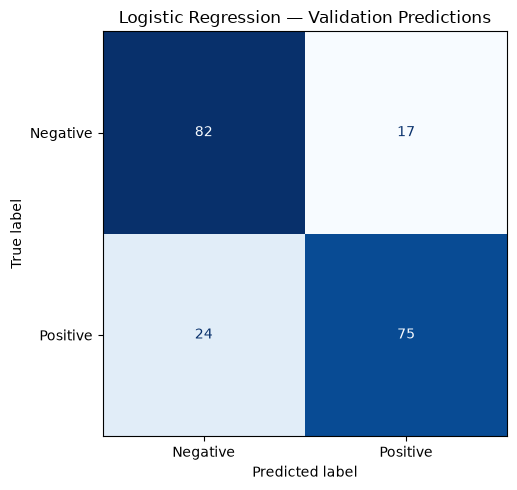

Misclassified sentences: 41 out of 198


,text,actual,predicted
5,It is super charged up for use as a small hybr...,Positive,Negative
11,The update procedure is difficult and cumbersome.,Negative,Positive
15,All in all I think it was a good investment.,Positive,Negative
19,I really wanted the Plantronics 510 to be the ...,Negative,Positive
22,Awkward to use and unreliable.,Negative,Positive
28,I was able to do voice dialing in the car with...,Positive,Negative
32,Very unreliable service from T-mobile !,Negative,Positive
34,It does everything the description said it would.,Positive,Negative
40,I got it because it was so small and adorable.,Positive,Negative
42,Comfortable fit - you need your headset to be ...,Positive,Negative


In [5]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    model_predictions,
    labels=[0, 1],
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("Logistic Regression — Validation Predictions")
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "day3_validation_confusion_matrix.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

# Keep predictions aligned with their original validation sentences.
validation_predictions = validation_df[
    ["text", "label"]
].copy()

validation_predictions["predicted_label"] = model_predictions

mistakes = validation_predictions.loc[
    validation_predictions["label"]
    != validation_predictions["predicted_label"]
].copy()

print(
    f"Misclassified sentences: {len(mistakes)} "
    f"out of {len(validation_df)}"
)

label_names = {0: "Negative", 1: "Positive"}

display(
    mistakes.head(10).assign(
        actual=lambda frame: frame["label"].map(label_names),
        predicted=lambda frame: frame["predicted_label"].map(label_names),
    )[["text", "actual", "predicted"]]
)

validation_predictions.to_csv(
    REPORTS_DIR / "validation_predictions.csv",
    index=False,
)

mistakes.to_csv(
    REPORTS_DIR / "validation_errors.csv",
    index=False,
)

In [6]:
# Display complete sentences for manual error analysis.
label_names = {0: "Negative", 1: "Positive"}

for number, (_, row) in enumerate(mistakes.head(8).iterrows(), start=1):
    print(f"Example {number}")
    print(f"Sentence: {row['text']}")
    print(f"Actual: {label_names[int(row['label'])]}")
    print(f"Predicted: {label_names[int(row['predicted_label'])]}")
    print()

Example 1
Sentence: It is super charged up for use as a small hybrid palmtop/camera/cellphone, and excels in those roles.
Actual: Positive
Predicted: Negative

Example 2
Sentence: The update procedure is difficult and cumbersome.
Actual: Negative
Predicted: Positive

Example 3
Sentence: All in all I think it was a good investment.
Actual: Positive
Predicted: Negative

Example 4
Sentence: I really wanted the Plantronics 510 to be the right one, but it has too many issues for me.The good
Actual: Negative
Predicted: Positive

Example 5
Sentence: Awkward to use and unreliable.
Actual: Negative
Predicted: Positive

Example 6
Sentence: I was able to do voice dialing in the car with no problem.
Actual: Positive
Predicted: Negative

Example 7
Sentence: Very unreliable service from T-mobile !
Actual: Negative
Predicted: Positive

Example 8
Sentence: It does everything the description said it would.
Actual: Positive
Predicted: Negative



In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline


# --------------------------------------------------
# 1. Locate the project folders
# --------------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

train_path = PROCESSED_DIR / "train.csv"
validation_path = PROCESSED_DIR / "validation.csv"

for path in [train_path, validation_path]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")


# --------------------------------------------------
# 2. Load training and validation data only
# --------------------------------------------------

train_df = pd.read_csv(train_path)
validation_df = pd.read_csv(validation_path)

for name, frame in [
    ("Training", train_df),
    ("Validation", validation_df),
]:
    assert frame["text"].notna().all(), f"{name} contains missing text"
    assert frame["label"].isin([0, 1]).all(), f"{name} has invalid labels"
    assert frame["normalized_text"].notna().all()

assert set(train_df["normalized_text"]).isdisjoint(
    set(validation_df["normalized_text"])
), "Repeated normalized text was found across the splits."

X_train = train_df["text"].to_list()
y_train = train_df["label"].to_numpy(dtype=int)

X_validation = validation_df["text"].to_list()
y_validation = validation_df["label"].to_numpy(dtype=int)

print(f"Training sentences: {len(train_df)}")
print(f"Validation sentences: {len(validation_df)}")
print("The final test set has not been loaded.")


# --------------------------------------------------
# 3. Create pipelines with identical TF-IDF settings
# --------------------------------------------------

comparison_models = {
    "Logistic regression": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True,
            ),
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42,
            ),
        ),
    ]),
    "Multinomial Naive Bayes": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True,
            ),
        ),
        (
            "classifier",
            MultinomialNB(alpha=1.0),
        ),
    ]),
}


# --------------------------------------------------
# 4. Train and evaluate each classifier
# --------------------------------------------------

comparison_rows = []
comparison_predictions: dict[str, np.ndarray] = {}

for name, model in comparison_models.items():
    # TF-IDF vocabulary and classifier are fitted on training data only.
    model.fit(X_train, y_train)

    predictions = np.asarray(
        model.predict(X_validation),
        dtype=int,
    )

    comparison_predictions[name] = predictions

    comparison_rows.append({
        "model": name,
        "validation_accuracy": accuracy_score(
            y_validation,
            predictions,
        ),
        "validation_macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "incorrect_predictions": int(
            np.count_nonzero(predictions != y_validation)
        ),
    })

day3_comparison = pd.DataFrame(comparison_rows)

print("\nVALIDATION MODEL COMPARISON")
display(day3_comparison.round(3))

day3_comparison.to_csv(
    REPORTS_DIR / "day3_classifier_comparison.csv",
    index=False,
)


# --------------------------------------------------
# 5. Compare the errors
# --------------------------------------------------

error_comparison = validation_df[["text", "label"]].copy()

for name, predictions in comparison_predictions.items():
    error_comparison[name] = predictions

lr_predictions = comparison_predictions["Logistic regression"]
nb_predictions = comparison_predictions["Multinomial Naive Bayes"]

lr_wrong = lr_predictions != y_validation
nb_wrong = nb_predictions != y_validation

both_wrong_mask = np.logical_and(lr_wrong, nb_wrong)
nb_only_correct_mask = np.logical_and(lr_wrong, ~nb_wrong)
lr_only_correct_mask = np.logical_and(~lr_wrong, nb_wrong)

error_summary = pd.Series(
    {
        "both_models_incorrect": int(
            np.count_nonzero(both_wrong_mask)
        ),
        "only_naive_bayes_correct": int(
            np.count_nonzero(nb_only_correct_mask)
        ),
        "only_logistic_regression_correct": int(
            np.count_nonzero(lr_only_correct_mask)
        ),
    },
    name="sentences",
)

print("\nERROR COMPARISON")
display(error_summary.to_frame())

both_wrong = error_comparison.loc[both_wrong_mask].copy()

label_names = {0: "Negative", 1: "Positive"}

print("\nEXAMPLES BOTH MODELS MISCLASSIFIED")

for number, (_, row) in enumerate(
    both_wrong.head(5).iterrows(),
    start=1,
):
    print(f"\nExample {number}")
    print(f"Sentence: {row['text']}")
    print(f"Actual: {label_names[int(row['label'])]}")
    print(
        "Logistic regression:",
        label_names[int(row["Logistic regression"])],
    )
    print(
        "Naive Bayes:",
        label_names[int(row["Multinomial Naive Bayes"])],
    )


# --------------------------------------------------
# 6. Save the predictions and error summary
# --------------------------------------------------

error_comparison.to_csv(
    REPORTS_DIR / "day3_classifier_predictions.csv",
    index=False,
)

error_summary.to_csv(
    REPORTS_DIR / "day3_error_comparison.csv",
)

print("\nComparison outputs saved.")
print("The final test set remains untouched.")

Training sentences: 591
Validation sentences: 198
The final test set has not been loaded.

VALIDATION MODEL COMPARISON


,model,validation_accuracy,validation_macro_f1,incorrect_predictions
0,Logistic regression,0.793,0.793,41
1,Multinomial Naive Bayes,0.788,0.788,42



ERROR COMPARISON


,sentences
both_models_incorrect,33
only_naive_bayes_correct,8
only_logistic_regression_correct,9



EXAMPLES BOTH MODELS MISCLASSIFIED

Example 1
Sentence: It is super charged up for use as a small hybrid palmtop/camera/cellphone, and excels in those roles.
Actual: Positive
Logistic regression: Negative
Naive Bayes: Negative

Example 2
Sentence: All in all I think it was a good investment.
Actual: Positive
Logistic regression: Negative
Naive Bayes: Negative

Example 3
Sentence: I really wanted the Plantronics 510 to be the right one, but it has too many issues for me.The good
Actual: Negative
Logistic regression: Positive
Naive Bayes: Positive

Example 4
Sentence: I was able to do voice dialing in the car with no problem.
Actual: Positive
Logistic regression: Negative
Naive Bayes: Negative

Example 5
Sentence: Very unreliable service from T-mobile !
Actual: Negative
Logistic regression: Positive
Naive Bayes: Positive

Comparison outputs saved.
The final test set remains untouched.


In [9]:
print("MODEL COMPARISON")
print(day3_comparison.round(3).to_string(index=False))

print("\nERROR COMPARISON")
print(error_summary.to_string())

MODEL COMPARISON
                  model  validation_accuracy  validation_macro_f1  incorrect_predictions
    Logistic regression                0.793                0.793                     41
Multinomial Naive Bayes                0.788                0.788                     42

ERROR COMPARISON
both_models_incorrect               33
only_naive_bayes_correct             8
only_logistic_regression_correct     9


In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer


# 1. Load training data and saved validation predictions.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORTS_DIR = PROJECT_ROOT / "reports"

training_data = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "train.csv"
)

prediction_data = pd.read_csv(
    REPORTS_DIR / "day3_classifier_predictions.csv"
)


# 2. Recreate the same vocabulary using training text only.
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
)

vectorizer.fit(training_data["text"].to_list())

validation_vectors = vectorizer.transform(
    prediction_data["text"].to_list()
)

# Count the vocabulary features recognized in each sentence.
prediction_data["recognized_features"] = np.asarray(
    validation_vectors.getnnz(axis=1)
).ravel()


# 3. Identify shared errors.
shared_error_mask = (
    (
        prediction_data["Logistic regression"]
        != prediction_data["label"]
    )
    & (
        prediction_data["Multinomial Naive Bayes"]
        != prediction_data["label"]
    )
)

prediction_data["both_models_wrong"] = shared_error_mask

print("VOCABULARY DIAGNOSTICS")

display(
    prediction_data.groupby("both_models_wrong")[
        "recognized_features"
    ]
    .agg(["count", "mean", "median", "min", "max"])
    .rename(index={
        False: "Not a shared error",
        True: "Both models wrong",
    })
    .round(2)
)

print(
    "Validation sentences with no recognized features:",
    int(prediction_data["recognized_features"].eq(0).sum()),
)


# 4. Inspect vocabulary coverage for a known shared error.
example = "All in all I think it was a good investment."

analyzer = vectorizer.build_analyzer()
vocabulary = vectorizer.vocabulary_

candidate_features = sorted(set(analyzer(example)))

recognized = [
    feature
    for feature in candidate_features
    if feature in vocabulary
]

unrecognized = [
    feature
    for feature in candidate_features
    if feature not in vocabulary
]

print("\nEXAMPLE SENTENCE")
print(example)

print("\nRecognized vocabulary features:")
print(recognized)

print("\nFeatures absent from the vocabulary:")
print(unrecognized)


# 5. Save the diagnostics.
prediction_data.to_csv(
    REPORTS_DIR / "day3_vocabulary_diagnostics.csv",
    index=False,
)

print("\nDiagnostics saved. The test set remains untouched.")

VOCABULARY DIAGNOSTICS


,count,mean,median,min,max
both_models_wrong,,,,,
Not a shared error,165,9.02,8.0,1,25
Both models wrong,33,12.61,13.0,0,25


Validation sentences with no recognized features: 1

EXAMPLE SENTENCE
All in all I think it was a good investment.

Recognized vocabulary features:
['all', 'good', 'in', 'it', 'it was', 'think', 'think it', 'was']

Features absent from the vocabulary:
['all in', 'all think', 'good investment', 'in all', 'investment', 'was good']

Diagnostics saved. The test set remains untouched.


In [11]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline


PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

train_data = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "train.csv"
)

validation_data = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "validation.csv"
)

X_train = train_data["text"].to_list()
y_train = train_data["label"].to_numpy(dtype=int)

X_validation = validation_data["text"].to_list()
y_validation = validation_data["label"].to_numpy(dtype=int)

experiment_rows = []

for minimum_frequency in [2, 1]:
    model = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=minimum_frequency,
                sublinear_tf=True,
            ),
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                random_state=42,
            ),
        ),
    ])

    model.fit(X_train, y_train)

    predictions = np.asarray(
        model.predict(X_validation),
        dtype=int,
    )

    fitted_vectorizer = model.named_steps["tfidf"]

    experiment_rows.append({
        "min_df": minimum_frequency,
        "vocabulary_size": len(fitted_vectorizer.vocabulary_),
        "validation_accuracy": accuracy_score(
            y_validation,
            predictions,
        ),
        "validation_macro_f1": f1_score(
            y_validation,
            predictions,
            average="macro",
            zero_division=0,
        ),
        "incorrect_predictions": int(
            np.count_nonzero(predictions != y_validation)
        ),
    })

vocabulary_experiment = pd.DataFrame(experiment_rows)

display(vocabulary_experiment.round(3))

vocabulary_experiment.to_csv(
    REPORTS_DIR / "day3_min_df_experiment.csv",
    index=False,
)

print("Only min_df changed. The final test set remains untouched.")

,min_df,vocabulary_size,validation_accuracy,validation_macro_f1,incorrect_predictions
0,2,1068,0.793,0.793,41
1,1,5086,0.803,0.803,39


Only min_df changed. The final test set remains untouched.
